# 🚦 CNN Traffic Sign Classification - Training Notebook

## 📁 Cấu trúc thư mục dự án
```
Traffic_Sign_Project/
├── Data_Pipeline/          # Xử lý dữ liệu
├── Training/               # (Notebook này)
│   ├── yolov8-detectsign.ipynb
│   └── cnn-detectsign.ipynb
├── Inference/              # Chạy inference
│   ├── Model_hybrid.py
│   ├── best.pt
│   └── traffic_sign_cnn.keras  # ← Model CNN sau khi train
└── Utils/
    └── helper_functions.py
```

## 🎯 Hướng dẫn sử dụng
1. **Upload notebook này lên Kaggle/Colab** (cần GPU)
2. **Upload dataset** đã xử lý từ `output_CNNdataset/` lên Kaggle
3. **Chạy các cells** theo thứ tự
4. **Download model** `.keras` và copy vào `Inference/traffic_sign_cnn.keras`

## ⚙️ Lưu ý về đường dẫn
- Các đường dẫn trong notebook được cấu hình cho **Kaggle environment**
- Nếu chạy local, cần sửa `DATASET_PATH` và các paths khác

# 🚀 HUẤN LUYỆN MÔ HÌNH CNN PHÂN LOẠI BIỂN BÁO (LIGHTWEIGHT)

## 1. Giới thiệu
Notebook này thực hiện huấn luyện mạng CNN nhẹ (Lightweight) để phân loại biển báo giao thông Việt Nam.
- **Input:** Ảnh 64x64
- **Mục tiêu:** Chạy Real-time trên Jetson Nano/Raspberry Pi.
- **Dataset:** `cnn-dataset-ts` (Train/Val).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix

# Kiểm tra GPU
print("TensorFlow Version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✅ Đã tìm thấy {len(gpus)} GPU: {gpus}")
else:
    print("⚠️ Không tìm thấy GPU. Hãy bật Accelerator trong Session Options!")

2026-01-03 16:10:30.935063: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1767456631.150008      17 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1767456631.213955      17 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1767456631.729388      17 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1767456631.729442      17 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1767456631.729446      17 computation_placer.cc:177] computation placer alr

TensorFlow Version: 2.19.0
⚠️ Không tìm thấy GPU. Hãy bật Accelerator trong Session Options!


2026-01-03 16:10:46.534081: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 2. Cấu hình Đường dẫn & Tham số
**Lưu ý:** Bạn cần thay đổi `DATASET_PATH` thành đường dẫn thực tế của dataset bạn đã upload lên Kaggle (thường nằm trong `/kaggle/input/...`).

In [2]:
# --- CẤU HÌNH (SỬA LẠI ĐƯỜNG DẪN CỦA BẠN Ở ĐÂY) ---
DATASET_PATH = '/kaggle/input/vietnam-traffic-sign-cnn-sota' 

TRAIN_DIR = os.path.join(DATASET_PATH, 'train')
VAL_DIR = os.path.join(DATASET_PATH, 'val')
TEST_DIR = os.path.join(DATASET_PATH, 'test')

# Tham số mô hình
IMG_SIZE = (64, 64)  # Kích thước ảnh đầu vào
BATCH_SIZE = 64      # Số lượng ảnh học một lần
EPOCHS = 50          # Số vòng lặp tối đa

# --- SỬA LỖI TẠI ĐÂY: Đếm số thư mục trong folder train ---
# Lọc chỉ lấy thư mục, bỏ qua file rác nếu có
class_folders = [d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d))]
NUM_CLASSES = len(class_folders)

print(f"✅ Đã tìm thấy: {NUM_CLASSES} lớp")
print(f"📂 Đường dẫn Train: {TRAIN_DIR}")

✅ Đã tìm thấy: 7 lớp
📂 Đường dẫn Train: /kaggle/input/vietnam-traffic-sign-cnn-sota/train


## 3. Data Generators & Augmentation
Chúng ta sử dụng `ImageDataGenerator` để load dữ liệu theo batch, giúp tiết kiệm RAM.
- **Train:** Có áp dụng Augmentation nhẹ (xoay, dịch chuyển) để chống Overfitting.
- **Val/Test:** Chỉ rescale (chia 255).

In [3]:
# Train Generator (Có tăng cường dữ liệu)
train_datagen = ImageDataGenerator(
    rescale=1./255,        # Chuẩn hóa pixel về [0, 1]
    rotation_range=10,     # Xoay nhẹ +/- 10 độ
    zoom_range=0.1,        # Zoom nhẹ
    fill_mode='nearest'
)

# Validation & Test Generator (Không tăng cường, chỉ chuẩn hóa)
test_datagen = ImageDataGenerator(rescale=1./255)

print("--- Đang load dữ liệu ---")
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    color_mode='rgb',
    shuffle=True
)

val_generator = test_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    color_mode='rgb',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    color_mode='rgb',
    shuffle=False
)

# Lưu lại tên các class
class_names = list(train_generator.class_indices.keys())
print(f"📌 Class Mapping: {train_generator.class_indices}")

--- Đang load dữ liệu ---
Found 19285 images belonging to 7 classes.
Found 3885 images belonging to 7 classes.
Found 2048 images belonging to 7 classes.
📌 Class Mapping: {'0_Cam_nguoc_chieu': 0, '1_Cam_dung_va_do': 1, '2_Cam_re': 2, '3_Gioi_han_toc_do': 3, '4_Cam_con_lai': 4, '5_Nguy_hiem': 5, '6_Hieu_lenh': 6}


## 4. Xây dựng Kiến trúc CNN (Lightweight)
Mô hình được thiết kế tối ưu cho Input `32x32`:
- Sử dụng 3 khối Conv2D + MaxPooling.
- Thêm `BatchNormalization` để train nhanh hơn.
- Thêm `Dropout` để tránh học vẹt (Overfitting).

In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, BatchNormalization, MaxPooling2D, Dropout, Flatten, Dense

def build_fixed_model(num_classes):
    model = Sequential([
        # --- THAY ĐỔI 1: Cập nhật Input Shape thành 64x64 ---
        Input(shape=(64, 64, 3)),
        
        # Block 1: Output shape -> 32x32
        Conv2D(32, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2, 2)),
        
        # Block 2: Output shape -> 16x16
        Conv2D(64, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.2),
        
        # Block 3: Output shape -> 8x8
        Conv2D(128, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.3),
        
        # --- THAY ĐỔI 2: Thêm Block 4 (Quan trọng cho ảnh 64x64) ---
        # Output shape -> 4x4 (Giúp Flatten không bị quá lớn)
        Conv2D(256, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.3),
        
        # Flatten & Dense
        Flatten(),
        
        # Tăng số lượng neuron ở Dense layer lên một chút vì đặc trưng phức tạp hơn
        Dense(512, activation='relu'), 
        BatchNormalization(),
        Dropout(0.5),
        
        # Output Layer
        Dense(num_classes, activation='softmax') 
    ])
    return model

# --- CẤU HÌNH SỐ LỚP ---
# Giả sử bạn có 7 lớp (dựa trên dataset cũ) hoặc số lớp thực tế của bộ CNN mới
CORRECT_NUM_CLASSES = 7  # Hãy thay số này bằng len(CLASS_NAMES) thực tế của bạn

# Khởi tạo lại model mới
model = build_fixed_model(CORRECT_NUM_CLASSES)

# Compile lại Model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Kiểm tra kiến trúc
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         3,591 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,493,639 (9.51 MB)

 Trainable params: 2,491,655 (9.50 MB)

 Non-trainable params: 1,984 (7.75 KB)

## 5. Bắt đầu Huấn luyện
Sử dụng Callbacks để tối ưu:
- `EarlyStopping`: Dừng train nếu model không cải thiện sau 10 epochs (tránh tốn thời gian).
- `ModelCheckpoint`: Chỉ lưu lại model tốt nhất (Best Model).
- `ReduceLROnPlateau`: Giảm tốc độ học nếu loss bị chững lại.

In [5]:
# Callbacks
checkpoint = ModelCheckpoint('best_cnn_traffic_sign.keras', 
                             monitor='val_accuracy', 
                             save_best_only=True, 
                             mode='max', 
                             verbose=1)

early_stop = EarlyStopping(monitor='val_loss', 
                           patience=10, 
                           restore_best_weights=True, 
                           verbose=1)

reduce_lr = ReduceLROnPlateau(monitor='val_loss', 
                              factor=0.5, 
                              patience=3, 
                              min_lr=1e-6, 
                              verbose=1)

# Training
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=[checkpoint, early_stop, reduce_lr]
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 528ms/step - accuracy: 0.6769 - loss: 1.0463
Epoch 1: val_accuracy improved from -inf to 0.59691, saving model to best_cnn_traffic_sign.keras
302/302 ━━━━━━━━━━━━━━━━━━━━ 179s 576ms/step - accuracy: 0.6772 - loss: 1.0452 - val_accuracy: 0.5969 - val_loss: 0.9637 - learning_rate: 0.0010
Epoch 2/50
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - accuracy: 0.8620 - loss: 0.3845
Epoch 2: val_accuracy improved from 0.59691 to 0.91506, saving model to best_cnn_traffic_sign.keras
302/302 ━━━━━━━━━━━━━━━━━━━━ 166s 551ms/step - accuracy: 0.8620 - loss: 0.3845 - val_accuracy: 0.9151 - val_loss: 0.2525 - learning_rate: 0.0010
Epoch 3/50
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 513ms/step - accuracy: 0.9040 - loss: 0.2779
Epoch 3: val_accuracy improved from 0.91506 to 0.95573, saving model to best_cnn_traffic_sign.keras
302/302 ━━━━━━━━━━━━━━━━━━━━ 162s 537ms/step - accuracy: 0.9040 - loss: 0.2779 - val_accuracy: 0.9557 - val_loss: 0.1510 - learning_rate: 0.0010
Epoc

## 6. Đánh giá & Trực quan hóa
Vẽ biểu đồ Loss/Accuracy và Ma trận nhầm lẫn (Confusion Matrix) để phân tích lỗi.

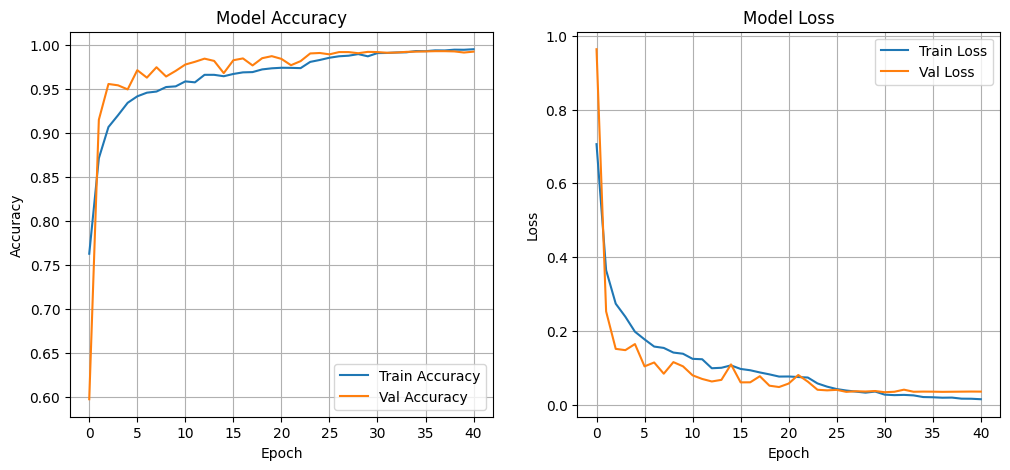


--- Đánh giá trên tập Test ---
32/32 ━━━━━━━━━━━━━━━━━━━━ 13s 410ms/step - accuracy: 0.9906 - loss: 0.0366
Test Accuracy: 99.07%
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step


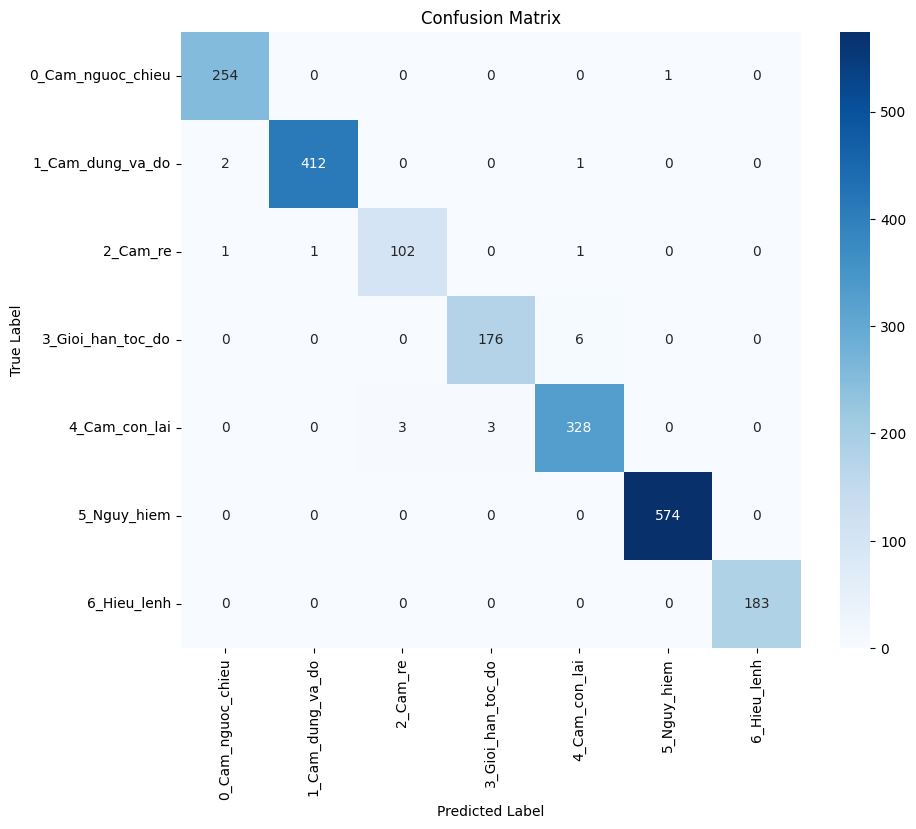

                   precision    recall  f1-score   support

0_Cam_nguoc_chieu       0.99      1.00      0.99       255
 1_Cam_dung_va_do       1.00      0.99      1.00       415
         2_Cam_re       0.97      0.97      0.97       105
3_Gioi_han_toc_do       0.98      0.97      0.98       182
    4_Cam_con_lai       0.98      0.98      0.98       334
      5_Nguy_hiem       1.00      1.00      1.00       574
      6_Hieu_lenh       1.00      1.00      1.00       183

         accuracy                           0.99      2048
        macro avg       0.99      0.99      0.99      2048
     weighted avg       0.99      0.99      0.99      2048



In [6]:
# 1. Vẽ biểu đồ Training
plt.figure(figsize=(12, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# 2. Đánh giá trên tập Test
print("\n--- Đánh giá trên tập Test ---")
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# 3. Confusion Matrix
# Reset generator để dự đoán từ đầu
test_generator.reset()
Y_pred = model.predict(test_generator)
y_pred = np.argmax(Y_pred, axis=1)
y_true = test_generator.classes

# Vẽ Heatmap
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# In báo cáo chi tiết
print(classification_report(y_true, y_pred, target_names=class_names))

In [7]:
# Cell này dùng để tải model về máy (nếu chạy trên Kaggle)
from IPython.display import FileLink
FileLink(r'best_cnn_traffic_sign.keras')

/kaggle/working/best_cnn_traffic_sign.keras